In [15]:
import matplotlib.pyplot as plt
import pandas as pd

In [4]:
PATH = "./lab1_DS.csv"

In [6]:
data = pd.read_csv(PATH)

In [7]:
print(data.columns.tolist())

x_column = input("Select X column: ")
y_column = input("Select Y column: ")

x = data[x_column]
y = data[y_column]

['YearsExperience', 'Salary']


In [8]:
def print_statistics(column):
    print("Count:", column.count())
    print("Min:", column.min())
    print("Max:", column.max())
    print("Mean:", column.mean())

In [13]:
print(x_column)
print_statistics(x)
print("=" * 15)
print(y_column)
print_statistics(y)

YearsExperience
Count: 35
Min: 1.1
Max: 13.5
Mean: 6.30857142857143
Salary
Count: 35
Min: 37731
Max: 139465
Mean: 83945.6


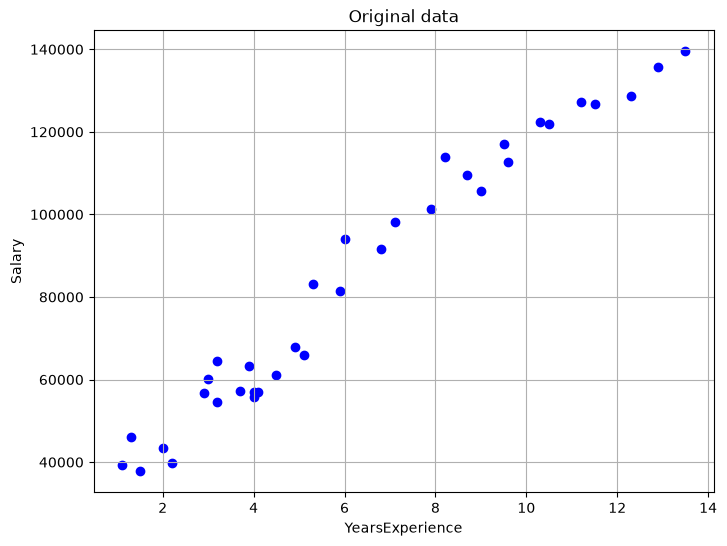

In [14]:
plt.figure(figsize=(8, 6))

plt.scatter(x, y, color="blue")

plt.xlabel(x_column)
plt.ylabel(y_column)
plt.title("Original data")

plt.grid(True)
plt.show()

In [16]:
def linear_regression(x, y):
    n = len(x)

    x_mean = sum(x) / n
    y_mean = sum(y) / n

    numerator = 0
    denominator = 0

    for i in range(n):
        numerator += (x[i] - x_mean) * (y[i] - y_mean)
        denominator += (x[i] - x_mean) ** 2

    if denominator == 0:
        raise ValueError("All X are similar")

    k = numerator / denominator
    b = y_mean - k * x_mean

    return k, b

In [17]:
k, b = linear_regression(x, y)

y_pred = [k * xi + b for xi in x]

print(k, b)
print(y_pred)

8731.941047062493 28859.526194531478
[np.float64(38464.66134630022), np.float64(40211.04955571272), np.float64(41957.437765125214), np.float64(46323.408288656465), np.float64(48069.796498068965), np.float64(54182.15523101271), np.float64(55055.34933571896), np.float64(56801.73754513146), np.float64(56801.73754513146), np.float64(61167.7080686627), np.float64(62914.0962780752), np.float64(63787.29038278145), np.float64(63787.29038278145), np.float64(64660.484487487694), np.float64(68153.2609063127), np.float64(71646.0373251377), np.float64(73392.42553455019), np.float64(75138.81374396269), np.float64(80377.97837220019), np.float64(81251.17247690645), np.float64(88236.72531455643), np.float64(90856.30762867517), np.float64(97841.86046632519), np.float64(100461.4427804439), np.float64(104827.41330397516), np.float64(107446.9956180939), np.float64(111812.96614162516), np.float64(112686.16024633142), np.float64(118798.51897927516), np.float64(120544.90718868765), np.float64(126657.265921631

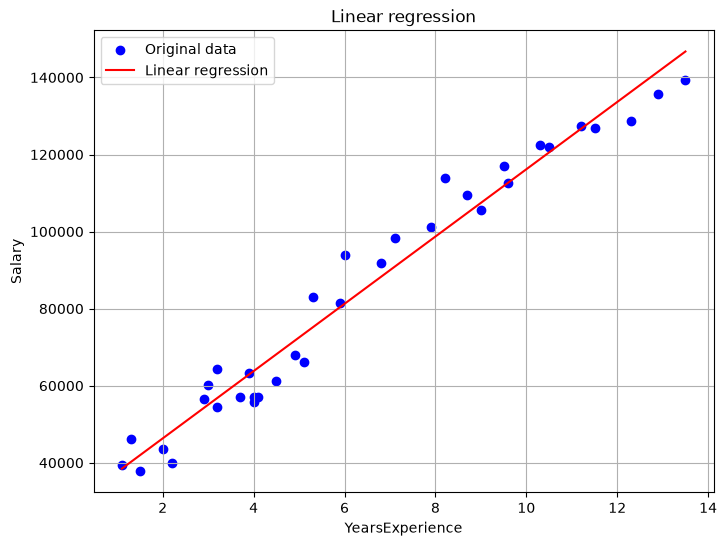

In [18]:
plt.figure(figsize=(8, 6))

plt.scatter(x, y, color="blue", label="Original data")
plt.plot(x, y_pred, color="red", label="Linear regression")

plt.xlabel(x_column)
plt.ylabel(y_column)
plt.title("Linear regression")

plt.legend()
plt.grid(True)
plt.show()

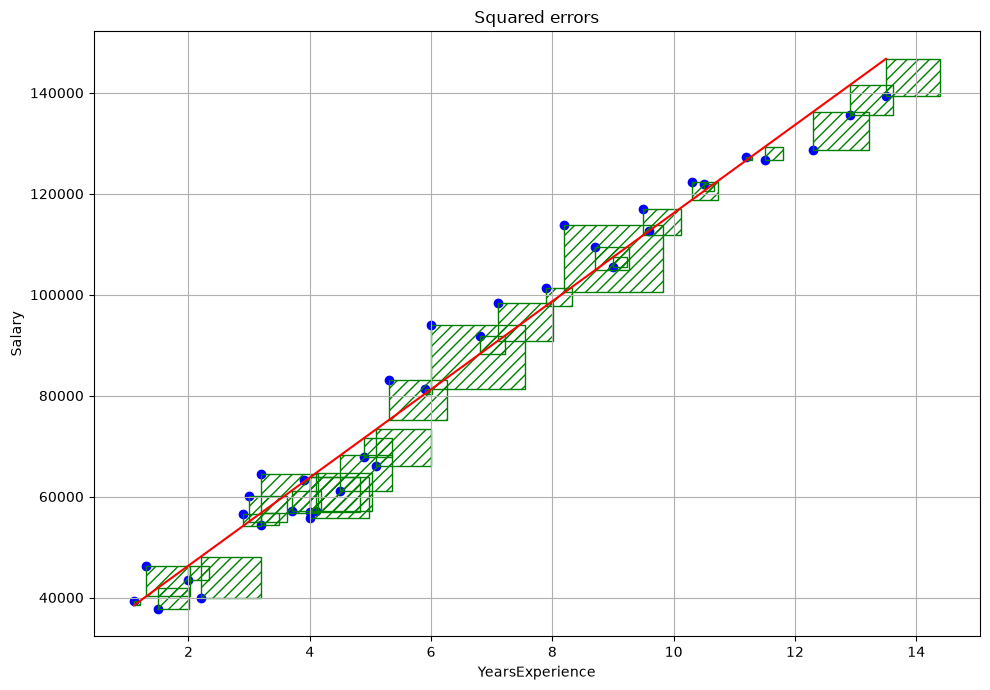

In [22]:
from matplotlib.patches import Rectangle

plt.figure(figsize=(10, 7))

plt.scatter(x, y, color="blue")
plt.plot(x, y_pred, color="red")

scale = (x.max() - x.min()) / (y.max() - y.min())

for xi, yi, y_hat in zip(x, y, y_pred):
    error = abs(yi - y_hat)

    square = Rectangle(
        (xi, min(yi, y_hat)),
        error * scale,
        error,
        edgecolor="green",
        facecolor="none",
        hatch="///"
    )

    plt.gca().add_patch(square)

plt.xlabel(x_column)
plt.ylabel(y_column)
plt.title("Squared errors")

plt.grid(True)
plt.tight_layout()
plt.show()